# MLP_JK_10 — Label permutation: does the skill depend on the true image–expression pairing?

**Why this notebook (sanity check from the proposal):** if the model really reads expression from the image, it should lose its skill when the training labels are shuffled. A second, within-slide shuffle tells us how much of the skill is **spot-level** (where in the tissue) vs. **slide-level** (which slide).

**Conditions** (only the **training** labels are shuffled; test labels are **never** shuffled)

| Condition | Training labels | What survives |
|---|---|---|
| **REAL** | normal | everything; must reproduce MLP_JK_Best |
| **P1** global shuffle | expression rows permuted across **all** training spots of the fold | nothing: pairing and slide levels are broken |
| **P2** within-slide shuffle | expression rows permuted only among spots of the **same** training section | each slide keeps its exact mean (its level); which spot has which values is broken |

- 3 shuffle draws per condition (permutation seeds 0, 1, 2); results are averaged, with the range shown.
- The **whole pipeline** runs on the shuffled training labels: inner validation (early stopping, epochs, `k`), the 3 final seeds, and ridge's alpha search. The MLP seeds are the same as REAL's, so only the pairing changes.
- The gene list (V_clean) and the PCA inputs are the same as REAL's: the PCA doesn't use labels, and a permutation doesn't change a gene's variance, detection rate or training mean (so the mean predictor is the same in every condition).

**Everything else is MLP_JK_Best:** setup E (center + 5×5 average) on V_clean, RAW target, the same folds, validation groups, MLP settings and ridge.

**Expectations (set before running)**
- P1: pooled and within-patient PCC near 0, MSE near the mean predictor's.
- P2: within-patient PCC near 0; pooled PCC and MSE show how much of REAL's skill comes from slide-level information alone. P2 can only lower the level error, not the pattern error.

**MLP_JK_Best is not changed** (a shuffled model is not a candidate).

**Reads** `~/JHU/BDD/datasets/BDD_HEST` (read only), `~/JHU/BDD/MLP_JK/results/` (standard_gene_rule.json, gene_symbols.csv, MLP_JK_Best).
**Saves** to `~/JHU/BDD/MLP_JK/results/MLP_JK_10/` and adds rows to `~/JHU/BDD/MLP_JK/results/all_results.csv`.

In [1]:
import os
import copy
import json
import time
import datetime
import numpy as np
import pandas as pd
import scipy.sparse
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.neighbors import NearestNeighbors

## Settings

**Paths:** `RULE_FILE` (V_clean), `SYMBOLS_FILE`, `BEST_DIR` (MLP_JK_Best's saved scores and genes; REAL must reproduce them), `LOG_RESULTS` (whether rows are added to `all_results.csv`).

**Shuffles:** `CONDITIONS`, `SHUFFLE_DRAWS` (the permutation seeds).

**Evaluation, inputs and MLP:** the same as MLP_JK_Best. **Check tolerances:** how far REAL may be from MLP_JK_Best before the notebook stops.

In [2]:
DATA_DIR = os.path.expanduser("~/JHU/BDD/datasets/BDD_HEST")
MLP_DIR = os.path.expanduser("~/JHU/BDD/MLP_JK")
RESULTS_DIR = os.path.join(MLP_DIR, "results")
RULE_FILE = os.path.join(RESULTS_DIR, "standard_gene_rule.json")
SYMBOLS_FILE = os.path.join(RESULTS_DIR, "gene_symbols.csv")
BEST_DIR = os.path.join(RESULTS_DIR, "MLP_JK_Best")
NOTEBOOK_NAME = "MLP_JK_10"
LOG_RESULTS = True
OUT_DIR = os.path.join(RESULTS_DIR, NOTEBOOK_NAME)
RESULTS_LOG = os.path.join(RESULTS_DIR, "all_results.csv")

CONDITIONS = {
    "REAL": "REAL",
    "P1": "P1 global shuffle",
    "P2": "P2 within-slide shuffle",
}
SHUFFLE_DRAWS = [0, 1, 2]

N_FOLDS = 4
N_INNER_FOLDS = 3
ALPHAS = np.logspace(-2, 7, 40)
MIN_TEST_SD = 0.05
SEED = 0

NEIGHBOR_DISTANCE = {"5x5": 3.0}
N_PCS = 256

HIDDEN_SIZE = 128
DROPOUT = 0.3
WEIGHT_DECAY = 1e-3
LEARNING_RATE = 3e-4
BATCH_SIZE = 256
MAX_EPOCHS = 100
PATIENCE = 10
SHRINK_FACTORS = [0.2, 0.4, 0.6, 0.8, 1.0]
N_VAL_GROUPS = 4
N_FINAL_SEEDS = 3

CHECK_MSE_TOLERANCE = 0.005
CHECK_PCC_TOLERANCE = 0.01
CHECK_VAL_PCC_TOLERANCE = 0.005
RIDGE_TOLERANCE = 1e-4

The gene rule, the model names, the device (Apple GPU `mps` if available, otherwise CPU), and fixed seeds.

In [3]:
with open(RULE_FILE) as f:
    gene_rule = json.load(f)
EXCLUDE_PREFIX = gene_rule["exclude_prefix"]
MIN_DETECTION = gene_rule["min_detection"]
N_GENES = gene_rule["n_genes"]
GENE_LIST = gene_rule["name"]
print(f"Gene list {GENE_LIST}: exclude '{EXCLUDE_PREFIX}...', detection >= {MIN_DETECTION}, top {N_GENES} by variance")

MODEL_NAMES = {
    "mean": "mean predictor",
    "ridge": "ridge raw",
    "E": "E 5x5 average",
}
MLP_SETUPS = {"E": "mean_5x5"}

if torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("Device:", device)

np.random.seed(SEED)
torch.manual_seed(SEED)

EXPRESSION_DIR = os.path.join(DATA_DIR, "expression")
EMBEDDING_DIR = os.path.join(DATA_DIR, "embeddings")
os.makedirs(OUT_DIR, exist_ok=True)


def save_figure(name):
    plt.savefig(os.path.join(OUT_DIR, name), dpi=150, bbox_inches="tight")

Gene list V_clean: exclude '__...', detection >= 0.1, top 50 by variance
Device: mps


## Step 1. Load embeddings and expression (copied from Notebook 5)

Each section's embedding file must list the same barcodes, in the same order, as the spot table, and each expression matrix must have one row per spot and one column per gene. The `assert` lines stop the notebook if not.

In [4]:
spot_table = pd.read_csv(os.path.join(DATA_DIR, "spot_table.csv"))
with open(os.path.join(DATA_DIR, "genes.txt")) as f:
    all_genes = np.array(f.read().split())

X_parts = []
Y_parts = []
spot_parts = []

for sample_id in spot_table["sample_id"].unique():
    section_spots = spot_table[spot_table["sample_id"] == sample_id].sort_values("row_in_sample")

    saved = np.load(os.path.join(EMBEDDING_DIR, f"{sample_id}.npz"), allow_pickle=True)
    assert np.array_equal(saved["barcode"], section_spots["barcode"].to_numpy()), \
        f"{sample_id}: embedding rows don't match the spot table"

    expression = scipy.sparse.load_npz(os.path.join(EXPRESSION_DIR, f"{sample_id}.npz"))
    assert expression.shape == (len(section_spots), len(all_genes)), \
        f"{sample_id}: expression shape doesn't match the spot table and genes.txt"

    X_parts.append(saved["embeddings"].astype(np.float32))
    Y_parts.append(expression)
    spot_parts.append(section_spots)

X_raw = np.concatenate(X_parts, axis=0)
Y = scipy.sparse.vstack(Y_parts).tocsc()
spots = pd.concat(spot_parts, ignore_index=True)
del X_parts, Y_parts
patient_array = spots["patient"].to_numpy()
section_array = spots["sample_id"].to_numpy()

print("X (embeddings):", X_raw.shape)
print("Y (log1p expression):", Y.shape)
print("Sections:", spots["sample_id"].nunique(), " Patients:", spots["patient"].nunique())

section_ids = np.unique(section_array)
section_number = np.searchsorted(section_ids, section_array)

X (embeddings): (30600, 4608)
Y (log1p expression): (30600, 11787)
Sections: 68  Patients: 23


## Step 2. Neighborhoods and patient folds (copied from MLP_JK_03)

The 5×5 neighborhood: every spot on the same section within 3.0 spot spacings, including the spot itself. Folds: `GroupKFold` by patient, the same 4 folds as always.

In [5]:
def find_neighborhoods(max_distance):
    neighborhoods = [None] * len(spots)
    for sample_id in np.unique(section_array):
        rows = np.where(section_array == sample_id)[0]
        xy = spots.loc[rows, ["x", "y"]].to_numpy().astype(np.float64)
        finder = NearestNeighbors().fit(xy)
        distances, _ = finder.kneighbors(xy, n_neighbors=2)
        spacing = np.median(distances[:, 1])
        nearby_lists = finder.radius_neighbors(xy, radius=max_distance * spacing, return_distance=False)
        for i, nearby in enumerate(nearby_lists):
            neighborhoods[rows[i]] = rows[nearby]
    return neighborhoods


def neighbor_mean(X, neighborhoods):
    X_smoothed = np.zeros_like(X)
    for i, nearby in enumerate(neighborhoods):
        X_smoothed[i] = X[nearby].mean(axis=0)
    return X_smoothed


neighborhoods = {}
for name, distance in NEIGHBOR_DISTANCE.items():
    neighborhoods[name] = find_neighborhoods(distance)
    sizes = np.array([len(n) for n in neighborhoods[name]])
    full = 9 if name == "3x3" else 25
    print(f"{name}: spots per neighborhood (incl. itself) mean {sizes.mean():.2f}, "
          f"min {sizes.min()}, max {sizes.max()} | full ({full}): {np.mean(sizes == full):.1%}")

5x5: spots per neighborhood (incl. itself) mean 21.25, min 2, max 27 | full (25): 18.2%


In [6]:
fold_of_spot = np.zeros(len(spots), dtype=int)
splitter = GroupKFold(n_splits=N_FOLDS)
for fold, (train_index, test_index) in enumerate(splitter.split(X_raw, groups=patient_array)):
    fold_of_spot[test_index] = fold

for fold in range(N_FOLDS):
    print(f"fold {fold}: {np.sum(fold_of_spot == fold)} test spots | {sorted(np.unique(patient_array[fold_of_spot == fold]))}")

fold_train_index = [np.where(fold_of_spot != fold)[0] for fold in range(N_FOLDS)]
fold_test_index = [np.where(fold_of_spot == fold)[0] for fold in range(N_FOLDS)]

fold 0: 7625 test spots | ['BC23209', 'BC23803', 'BC23810', 'BC23895', 'BC23901', 'BC23903']
fold 1: 7950 test spots | ['BC23268', 'BC23287', 'BC23377', 'BC23450', 'BC23506', 'BC24220']
fold 2: 7876 test spots | ['BC23269', 'BC23270', 'BC23277', 'BC23508', 'BC23567', 'BC24105']
fold 3: 7149 test spots | ['BC23272', 'BC23288', 'BC23944', 'BC24044', 'BC24223']


## Step 3. The gene list, V_clean, from the rule file

`standard_genes(train_index)` applies the rule on the fold's training spots: drop the excluded bins, keep genes with count > 0 in at least 10% of the spots, take the top 50 by variance. The lists must equal MLP_JK_Best's genes in every fold.

In [7]:
symbols = pd.read_csv(SYMBOLS_FILE)
symbol_of = dict(zip(symbols["ensembl_id"], symbols["symbol"]))
is_excluded = np.char.startswith(all_genes.astype(str), EXCLUDE_PREFIX)


def standard_genes(train_index):
    Y_train = Y[train_index]
    detection = np.asarray((Y_train > 0).mean(axis=0)).ravel()
    mean = np.asarray(Y_train.mean(axis=0)).ravel()
    variance = np.asarray(Y_train.multiply(Y_train).mean(axis=0)).ravel() - mean ** 2
    candidates = np.where(~is_excluded & (detection >= MIN_DETECTION))[0]
    return candidates[np.argsort(variance[candidates])[::-1][:N_GENES]]


fold_genes = [standard_genes(fold_train_index[fold]) for fold in range(N_FOLDS)]

reference_genes = pd.read_csv(os.path.join(BEST_DIR, "genes.csv"))
for fold in range(N_FOLDS):
    saved = reference_genes[reference_genes["fold"] == fold].sort_values("rank")["ensembl_id"].tolist()
    assert saved == list(all_genes[fold_genes[fold]]), f"fold {fold}: genes differ from MLP_JK_Best"
print("V_clean equals MLP_JK_Best's genes in every fold.")
for fold in range(N_FOLDS):
    print(f"fold {fold}: " + ", ".join(symbol_of[g] for g in all_genes[fold_genes[fold]][:10]) + ", ...")

V_clean equals MLP_JK_Best's genes in every fold.
fold 0: IGLL5, TFF3, MUC1, RPS3, S100A9, H2AJ, MGP, ERBB2, KRT19, NHERF1, ...
fold 1: TFF3, IGLL5, S100A9, ERBB2, NHERF1, MUC1, COX6C, MGP, KRT19, B2M, ...
fold 2: TFF3, IGLL5, RPS3, ERBB2, KRT19, MUC1, MGP, NHERF1, H2AJ, AZGP1, ...
fold 3: TFF3, IGLL5, RPS3, ERBB2, H2AJ, MUC1, MGP, KRT19, NHERF1, S100A9, ...


## Step 4. Scoring and the error split

**`score_model`** (copied from Notebook 5): per gene, pooled PCC and NRMSE (genes with test SD < 0.05 get no NRMSE), and the same within each test patient.

**`error_parts`** (from MLP_JK_06): a fold's MSE split into **level error** (each test slide's predicted mean vs. its true mean) and **pattern error** (what's left inside each slide). It checks that the two add up to the MSE.

In [8]:
def pcc(a, b):
    if np.std(a) < 1e-6 or np.std(b) < 1e-6:
        return np.nan
    return np.corrcoef(a, b)[0, 1]


def score_model(model_name, fold_results, prediction_key):
    pooled_rows = []
    within_rows = []
    for r in fold_results:
        y_true = r["y_test"]
        y_pred = r[prediction_key]
        test_patients = patient_array[r["test_index"]]

        for g, gene in enumerate(r["genes"]):
            sd = np.std(y_true[:, g])
            rmse = np.sqrt(np.mean((y_true[:, g] - y_pred[:, g]) ** 2))
            pooled_rows.append({
                "model": model_name, "fold": r["fold"], "gene": gene,
                "PCC": pcc(y_true[:, g], y_pred[:, g]),
                "NRMSE": rmse / sd if sd >= MIN_TEST_SD else np.nan,
                "alpha": r["alpha"][g] if prediction_key == "y_pred" else np.nan,
            })

        for patient in np.unique(test_patients):
            rows = test_patients == patient
            for g, gene in enumerate(r["genes"]):
                t = y_true[rows, g]
                p = y_pred[rows, g]
                sd = np.std(t)
                if sd < MIN_TEST_SD:
                    continue
                centered_mse = np.mean(((t - t.mean()) - (p - p.mean())) ** 2)
                within_rows.append({
                    "model": model_name, "fold": r["fold"], "patient": patient, "gene": gene,
                    "PCC_within": pcc(t, p),
                    "NRMSE_within": np.sqrt(np.mean((t - p) ** 2)) / sd,
                    "NRMSE_centered": np.sqrt(centered_mse) / sd,
                })
    return pd.DataFrame(pooled_rows), pd.DataFrame(within_rows)


def split_error(y_true, y_pred, rows):
    sections = section_number[rows]
    level_error = np.zeros(y_true.shape[1])
    pattern_error = np.zeros(y_true.shape[1])
    for s in np.unique(sections):
        in_section = sections == s
        error = y_true[in_section] - y_pred[in_section]
        share = in_section.mean()
        level_error += share * error.mean(axis=0) ** 2
        pattern_error += share * error.var(axis=0)
    return level_error.mean(), pattern_error.mean()


def error_parts(result):
    scored = result["y_test"].std(axis=0) >= MIN_TEST_SD
    y_true = result["y_test"][:, scored]
    y_pred = result["y_pred"][:, scored]
    mse = np.mean((y_true - y_pred) ** 2)
    level_error, pattern_error = split_error(y_true, y_pred, result["test_index"])
    assert abs(level_error + pattern_error - mse) < 1e-6, "level + pattern doesn't add up to the MSE"
    return mse, level_error, pattern_error, scored.sum()

## Step 5. PCA inputs for every fold

On each fold's training spots: StandardScaler + PCA 256 of the center embeddings and of the 5×5 averages. E = `center` + `mean_5x5`; ridge uses `center`.

In [9]:
def pca_256(X, train_index):
    scaler = StandardScaler()
    pca = PCA(n_components=N_PCS, random_state=SEED)
    pca.fit(scaler.fit_transform(X[train_index]))
    return pca.transform(scaler.transform(X)).astype(np.float32)


start_time = time.time()
X_mean_5x5 = neighbor_mean(X_raw, neighborhoods["5x5"])
fold_inputs = []
for fold in range(N_FOLDS):
    train_index = fold_train_index[fold]
    fold_inputs.append({"center": pca_256(X_raw, train_index), "mean_5x5": pca_256(X_mean_5x5, train_index)})
    print(f"fold {fold}: PCA inputs done ({(time.time() - start_time) / 60:.1f} min)", flush=True)
del X_raw, X_mean_5x5

fold 0: PCA inputs done (0.2 min)


fold 1: PCA inputs done (0.3 min)


fold 2: PCA inputs done (0.4 min)


fold 3: PCA inputs done (0.6 min)


## Step 6. Ridge, the MLP, and shrinkage (copied from Notebook 5 and MLP_JK_03)

**Ridge:** one alpha per gene, chosen by 3-fold patient-grouped cross-validation inside the training patients.

**The MLP:** input → Linear(input, 128) → ReLU → Dropout 0.3 → Linear(128, 50). Adam (weight decay 1e-3), MSE loss on standardized genes, batches of 256, early stopping with patience 10 on validation patients. `shrink` = `train_mean + k × (prediction − train_mean)`.

In [10]:
def choose_alpha_per_gene(P_train, y_train, inner_groups):
    n_inner = min(N_INNER_FOLDS, len(np.unique(inner_groups)))
    inner_splits = GroupKFold(n_splits=n_inner).split(P_train, groups=inner_groups)

    errors = np.zeros((len(ALPHAS), y_train.shape[1]))
    for inner_train, inner_val in inner_splits:
        for a, alpha in enumerate(ALPHAS):
            model = Ridge(alpha=alpha)
            model.fit(P_train[inner_train], y_train[inner_train])
            prediction = model.predict(P_train[inner_val])
            errors[a] += np.mean((prediction - y_train[inner_val]) ** 2, axis=0)

    best = np.argmin(errors, axis=0)
    return ALPHAS[best]


def fit_and_predict(P_train, y_train, P_test, alpha_per_gene):
    y_pred = np.zeros((P_test.shape[0], y_train.shape[1]))
    for alpha in np.unique(alpha_per_gene):
        genes_with_this_alpha = np.where(alpha_per_gene == alpha)[0]
        model = Ridge(alpha=alpha)
        model.fit(P_train, y_train[:, genes_with_this_alpha])
        y_pred[:, genes_with_this_alpha] = model.predict(P_test).reshape(len(P_test), -1)
    return y_pred

In [11]:
class MLP(nn.Module):
    def __init__(self, n_inputs, n_hidden, n_outputs, dropout):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(n_inputs, n_hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(n_hidden, n_outputs),
        )

    def forward(self, x):
        return self.layers(x)


def to_device(array):
    return torch.tensor(np.asarray(array), dtype=torch.float32, device=device)


def predict(trained, P_device, rows):
    model = trained["model"]
    model.eval()
    outputs = []
    with torch.no_grad():
        for start in range(0, len(rows), 4096):
            batch_rows = torch.tensor(rows[start:start + 4096], device=device)
            outputs.append(model(P_device[batch_rows]).cpu().numpy())
    y_scaled = np.concatenate(outputs, axis=0)
    return y_scaled * trained["gene_sd"] + trained["gene_mean"]


def shrink(y_pred, train_mean, k):
    return train_mean + k * (y_pred - train_mean)


def train_mlp(P_device, y_fold, train_rows, val_rows, n_epochs, seed):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)

    gene_mean = y_fold[train_rows].mean(axis=0)
    gene_sd = y_fold[train_rows].std(axis=0)
    y_scaled = to_device((y_fold - gene_mean) / gene_sd)

    model = MLP(P_device.shape[1], HIDDEN_SIZE, N_GENES, DROPOUT).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    loss_function = nn.MSELoss()

    trained = {
        "model": model,
        "gene_mean": gene_mean,
        "gene_sd": gene_sd,
        "history": [],
        "best_epoch": n_epochs,
    }

    best_val_loss = np.inf
    best_weights = None
    for epoch in range(1, n_epochs + 1):
        model.train()
        shuffled = rng.permutation(train_rows)
        batch_losses = []
        for start in range(0, len(shuffled), BATCH_SIZE):
            batch_rows = torch.tensor(shuffled[start:start + BATCH_SIZE], device=device)
            loss = loss_function(model(P_device[batch_rows]), y_scaled[batch_rows])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            batch_losses.append(loss.item())
        train_loss = np.mean(batch_losses)

        if val_rows is None:
            trained["history"].append({"epoch": epoch, "train_loss": train_loss, "val_loss": np.nan})
            continue

        val_pred = predict(trained, P_device, val_rows)
        val_loss = np.mean(((val_pred - y_fold[val_rows]) / gene_sd) ** 2)
        trained["history"].append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss})

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            trained["best_epoch"] = epoch
            best_weights = copy.deepcopy(model.state_dict())
        elif epoch - trained["best_epoch"] >= PATIENCE:
            break

    if best_weights is not None:
        model.load_state_dict(best_weights)
    return trained

## Step 7. Shuffling the training labels

**`shuffled_labels(y_fold, train_index, condition, draw)`** returns a copy of the fold's gene matrix in which only the **training** rows are shuffled (test rows stay `NaN`):
- **REAL:** unchanged.
- **P1:** one random permutation of all training spots: each training spot gets the expression of a random other training spot (any slide, any patient).
- **P2:** a separate permutation inside each training section: each spot gets the expression of a random spot **from the same slide**, so every slide keeps exactly the same mean.

The printout checks on fold 0 (in float64, so float32 rounding doesn't blur the answer) that P1 and P2 keep each gene's training mean, and that P2 keeps every section's mean.

In [12]:
def shuffled_labels(y_fold, train_index, condition, draw):
    y = y_fold.copy()
    if condition == "REAL":
        return y
    rng = np.random.default_rng(draw)
    if condition == "P1":
        y[train_index] = y_fold[rng.permutation(train_index)]
    elif condition == "P2":
        train_sections = section_number[train_index]
        for s in np.unique(train_sections):
            rows = train_index[train_sections == s]
            y[rows] = y_fold[rng.permutation(rows)]
    else:
        raise ValueError(condition)
    return y


train_index = fold_train_index[0]
y_check = Y[:, fold_genes[0]].toarray().astype(np.float64)
for condition in ["P1", "P2"]:
    y_shuffled = shuffled_labels(y_check, train_index, condition, 0)
    same_gene_means = np.allclose(y_shuffled[train_index].mean(axis=0), y_check[train_index].mean(axis=0))
    same_section_means = all(np.allclose(y_shuffled[train_index][section_number[train_index] == s].mean(axis=0),
                                         y_check[train_index][section_number[train_index] == s].mean(axis=0))
                             for s in np.unique(section_number[train_index]))
    moved = np.mean(np.any(y_shuffled[train_index] != y_check[train_index], axis=1))
    print(f"{condition}: gene means kept {same_gene_means}, section means kept {same_section_means}, "
          f"training spots with different values {moved:.1%}")
del y_check, y_shuffled

P1: gene means kept True, section means kept False, training spots with different values 100.0%
P2: gene means kept True, section means kept True, training spots with different values 99.8%


## Step 8. One fold under one condition, start to finish

The same as MLP_JK_Best, except that every training step reads the shuffled labels:

| Step | Uses |
|---|---|
| V_clean, PCA inputs | as in REAL (not affected by the shuffle) |
| Training mean (mean predictor) | training spots; the same in every condition |
| Ridge alphas | 3-fold patient-grouped CV on the shuffled training labels |
| For each of the 4 validation groups | E trained on the fit patients with early stopping on the validation patients, both with shuffled labels |
| `k`, epochs | chosen on those validation scores (shuffled labels) |
| Final model | E on all training patients (shuffled labels), 3 seeds, averaged |
| Test patients | **true** labels, used once for scoring |

In [13]:
def validation_groups(train_index):
    groups = patient_array[train_index]
    splits = []
    for inner_fit, inner_val in GroupKFold(n_splits=N_VAL_GROUPS).split(train_index, groups=groups):
        splits.append((train_index[inner_fit], train_index[inner_val]))
    return splits


def run_fold(fold, condition, draw):
    gene_index = fold_genes[fold]
    genes = all_genes[gene_index]
    train_index = fold_train_index[fold]
    test_index = fold_test_index[fold]
    no_alpha = np.full(N_GENES, np.nan)

    y_fold = Y[:, gene_index].toarray()
    y_fold[test_index] = np.nan
    y_fold = shuffled_labels(y_fold, train_index, condition, draw)
    y_test = Y[test_index][:, gene_index].toarray()
    train_mean = y_fold[train_index].mean(axis=0)
    center = fold_inputs[fold]["center"]

    def as_result(prediction, alpha=no_alpha):
        return {"fold": fold, "test_index": test_index, "genes": genes, "y_test": y_test,
                "y_pred": prediction, "alpha": alpha}

    test_results = {"mean": as_result(np.tile(train_mean, (len(test_index), 1)))}

    alpha_per_gene = choose_alpha_per_gene(center[train_index], y_fold[train_index], patient_array[train_index])
    ridge_prediction = fit_and_predict(center[train_index], y_fold[train_index], center[test_index], alpha_per_gene)
    test_results["ridge"] = as_result(ridge_prediction, alpha_per_gene)

    P_device = to_device(np.concatenate([center, fold_inputs[fold]["mean_5x5"]], axis=1))
    val_rows = []
    for group, (fit_rows, val_index) in enumerate(validation_groups(train_index)):
        fit_mean = y_fold[fit_rows].mean(axis=0)
        val_result = {
            "fold": fold,
            "test_index": val_index,
            "genes": genes,
            "y_test": y_fold[val_index],
            "y_mean": np.tile(fit_mean, (len(val_index), 1)),
            "alpha": no_alpha,
        }
        mean_scores, _ = score_model("mean predictor", [val_result], "y_mean")

        trained = train_mlp(P_device, y_fold, fit_rows, val_index, MAX_EPOCHS, SEED)
        val_pred = predict(trained, P_device, val_index)
        for k in SHRINK_FACTORS:
            val_result["y_pred"] = shrink(val_pred, fit_mean, k)
            scores, _ = score_model("MLP", [val_result], "y_pred")
            val_rows.append({
                "condition": condition, "draw": draw, "fold": fold, "val_group": group, "k": k,
                "val_PCC": scores["PCC"].mean(),
                "val_NRMSE": scores["NRMSE"].mean(),
                "val_mean_predictor_NRMSE": mean_scores["NRMSE"].mean(),
                "best_epoch": trained["best_epoch"],
            })

    val_table = pd.DataFrame(val_rows)
    by_k = val_table.groupby("k").agg(
        val_PCC=("val_PCC", "mean"),
        val_NRMSE=("val_NRMSE", "mean"),
        val_mean_predictor_NRMSE=("val_mean_predictor_NRMSE", "mean"),
        epochs=("best_epoch", "median"),
    ).reset_index()
    chosen = by_k.loc[by_k["val_NRMSE"].idxmin()].to_dict()
    chosen["final_epochs"] = max(1, int(round(chosen["epochs"])))
    chosen.update({"condition": condition, "draw": draw, "fold": fold})

    seed_predictions = []
    for seed_number in range(N_FINAL_SEEDS):
        final = train_mlp(P_device, y_fold, train_index, None, chosen["final_epochs"], SEED + seed_number)
        seed_predictions.append(predict(final, P_device, test_index))
    del P_device

    test_results["E"] = as_result(shrink(np.mean(seed_predictions, axis=0), train_mean, chosen["k"]))
    seed_results = [as_result(shrink(p, train_mean, chosen["k"])) for p in seed_predictions]
    return test_results, seed_results, val_table, chosen

## Step 9. REAL first, and check it against MLP_JK_Best

REAL is exactly MLP_JK_Best, so it must reproduce it: test MSE within 0.005, pooled PCC within 0.01, validation PCC within 0.005, ridge to 4 decimals. Otherwise the notebook stops.

`score_results` (from MLP_JK_Best) gives per-fold and overall scores, including the level/pattern split.

In [14]:
def score_results(fold_results, model_name):
    pooled, within = score_model(model_name, fold_results, "y_pred")
    rows = []
    for r in fold_results:
        mse, level_error, pattern_error, n_scored = error_parts(r)
        fold = r["fold"]
        rows.append({
            "model": model_name, "fold": fold, "MSE": mse, "level_error": level_error,
            "pattern_error": pattern_error, "genes_scored": n_scored,
            "PCC": pooled.loc[pooled["fold"] == fold, "PCC"].mean(),
            "NRMSE": pooled.loc[pooled["fold"] == fold, "NRMSE"].mean(),
            "PCC_within": within.loc[within["fold"] == fold, "PCC_within"].mean(),
        })
    folds = pd.DataFrame(rows)
    folds["level_share"] = folds["level_error"] / folds["MSE"]
    n = folds["genes_scored"]
    overall = {
        "test_MSE": np.sum(folds["MSE"] * n) / n.sum(),
        "pooled_PCC": pooled["PCC"].mean(),
        "within_PCC": within["PCC_within"].mean(),
        "NRMSE": pooled["NRMSE"].mean(),
        "level_error": np.sum(folds["level_error"] * n) / n.sum(),
        "pattern_error": np.sum(folds["pattern_error"] * n) / n.sum(),
    }
    overall["level_share"] = overall["level_error"] / overall["test_MSE"]
    return folds, overall, pooled, within



RUNS = [("REAL", 0)] + [(condition, draw) for condition in ["P1", "P2"] for draw in SHUFFLE_DRAWS]
results = {}
seed_results = {}
val_tables = []
chosen_rows = []


def run_condition(condition, draw):
    start_time = time.time()
    results[(condition, draw)] = {model: [] for model in MODEL_NAMES}
    seed_results[(condition, draw)] = [[] for _ in range(N_FINAL_SEEDS)]
    for fold in range(N_FOLDS):
        fold_results, fold_seed_results, val_table, chosen = run_fold(fold, condition, draw)
        for model in MODEL_NAMES:
            results[(condition, draw)][model].append(fold_results[model])
        for seed_number, seed_result in enumerate(fold_seed_results):
            seed_results[(condition, draw)][seed_number].append(seed_result)
        val_tables.append(val_table)
        chosen_rows.append(chosen)
        if device.type == "mps":
            torch.mps.empty_cache()
    ks = [c["k"] for c in chosen_rows[-N_FOLDS:]]
    epochs = [c["final_epochs"] for c in chosen_rows[-N_FOLDS:]]
    print(f"{CONDITIONS[condition]}, draw {draw}: k = {ks}, epochs = {epochs}  "
          f"({(time.time() - start_time) / 60:.1f} min)", flush=True)


run_condition("REAL", 0)

best_summary = pd.read_csv(os.path.join(BEST_DIR, "summary.csv")).set_index("model")
real_val_pcc = np.mean([c["val_PCC"] for c in chosen_rows if c["condition"] == "REAL"])
check_rows = []
for model, model_name, metric, tolerance in [
        ("E", "E 5x5 average", "test_MSE", CHECK_MSE_TOLERANCE),
        ("E", "E 5x5 average", "pooled_PCC", CHECK_PCC_TOLERANCE),
        ("E", "E 5x5 average", "val_PCC", CHECK_VAL_PCC_TOLERANCE),
        ("ridge", "ridge raw", "test_MSE", RIDGE_TOLERANCE),
        ("ridge", "ridge raw", "pooled_PCC", RIDGE_TOLERANCE)]:
    if metric == "val_PCC":
        here = real_val_pcc
    else:
        here = score_results(results[("REAL", 0)][model], model_name)[1][metric]
    saved = best_summary.loc[model_name, metric]
    check_rows.append({"model": model_name, "metric": metric, "REAL": here, "MLP_JK_Best": saved,
                       "difference": here - saved, "ok": abs(here - saved) <= tolerance})
reproduction_check = pd.DataFrame(check_rows)
print(reproduction_check.round(4).to_string(index=False))
assert reproduction_check["ok"].all(), "REAL doesn't reproduce MLP_JK_Best. Stop and check before going further."
print("REAL reproduces MLP_JK_Best.")

REAL, draw 0: k = [0.4, 0.4, 0.4, 0.4], epochs = [12, 12, 18, 10]  (0.8 min)


        model     metric   REAL  MLP_JK_Best  difference   ok
E 5x5 average   test_MSE 0.9451       0.9451        -0.0 True
E 5x5 average pooled_PCC 0.2053       0.2053         0.0 True
E 5x5 average    val_PCC 0.2376       0.2376         0.0 True
    ridge raw   test_MSE 0.9674       0.9674         0.0 True
    ridge raw pooled_PCC 0.1945       0.1945         0.0 True
REAL reproduces MLP_JK_Best.


## Step 10. The shuffled conditions: P1 and P2, 3 draws each

In [15]:
for condition, draw in RUNS[1:]:
    run_condition(condition, draw)

val_scores = pd.concat(val_tables, ignore_index=True)
chosen_settings = pd.DataFrame(chosen_rows)
pd.set_option("display.width", 250)
print(chosen_settings[["condition", "draw", "fold", "k", "final_epochs", "val_PCC", "val_NRMSE",
                       "val_mean_predictor_NRMSE"]].round(4).to_string(index=False))

P1 global shuffle, draw 0: k = [0.2, 0.2, 0.2, 0.2], epochs = [8, 9, 8, 8]  (0.6 min)


P1 global shuffle, draw 1: k = [0.2, 0.2, 0.2, 0.2], epochs = [8, 9, 8, 8]  (0.6 min)


P1 global shuffle, draw 2: k = [0.2, 0.2, 0.2, 0.2], epochs = [8, 9, 8, 8]  (0.6 min)


P2 within-slide shuffle, draw 0: k = [0.2, 0.2, 0.2, 0.2], epochs = [18, 16, 20, 12]  (0.9 min)


P2 within-slide shuffle, draw 1: k = [0.4, 0.2, 0.2, 0.2], epochs = [16, 16, 20, 12]  (0.9 min)


P2 within-slide shuffle, draw 2: k = [0.4, 0.2, 0.2, 0.2], epochs = [13, 17, 20, 11]  (0.9 min)


condition  draw  fold   k  final_epochs  val_PCC  val_NRMSE  val_mean_predictor_NRMSE
     REAL     0     0 0.4            12   0.2982     1.0978                    1.1441
     REAL     0     1 0.4            12   0.1907     1.1077                    1.1268
     REAL     0     2 0.4            18   0.2108     1.0601                    1.0978
     REAL     0     3 0.4            10   0.2506     1.0560                    1.0825
       P1     0     0 0.2             8   0.0002     1.0028                    1.0001
       P1     0     1 0.2             9  -0.0019     1.0029                    1.0001
       P1     0     2 0.2             8  -0.0003     1.0031                    1.0001
       P1     0     3 0.2             8   0.0023     1.0026                    1.0001
       P1     1     0 0.2             8   0.0007     1.0029                    1.0001
       P1     1     1 0.2             9  -0.0013     1.0029                    1.0001
       P1     1     2 0.2             8  -0.0022     1

## Step 11. Results

**Per run** (condition × draw × model): per-fold and overall scores. **MSE ratio** = model MSE ÷ the mean predictor's MSE in the same fold (the mean predictor is identical in every condition), so 1 = no better than guessing the training average.

**Summary** per model and condition: the mean over the 3 draws, with the lowest and highest draw. For REAL (one run), the range is over the 3 final model seeds instead.

In [16]:
METRICS = ["test_MSE", "MSE_ratio", "pooled_PCC", "within_PCC", "NRMSE", "level_error", "pattern_error", "level_share"]
mean_folds, mean_overall, _, _ = score_results(results[("REAL", 0)]["mean"], "mean predictor")

run_rows = []
fold_tables = []
pooled_tables = []
within_tables = []
for condition, draw in RUNS:
    for model in ["ridge", "E"]:
        folds, overall, pooled_part, within_part = score_results(results[(condition, draw)][model], MODEL_NAMES[model])
        folds["MSE_ratio"] = folds["MSE"].to_numpy() / mean_folds["MSE"].to_numpy()
        for table in [folds, pooled_part, within_part]:
            table["condition"] = condition
            table["draw"] = draw
        fold_tables.append(folds)
        pooled_tables.append(pooled_part)
        within_tables.append(within_part)

        row = {"model": MODEL_NAMES[model], "condition": condition, "draw": draw}
        row.update(overall)
        row["MSE_ratio"] = overall["test_MSE"] / mean_overall["test_MSE"]
        if model == "E":
            c = chosen_settings[(chosen_settings["condition"] == condition) & (chosen_settings["draw"] == draw)]
            row["val_PCC"] = c["val_PCC"].mean()
            row["val_NRMSE"] = c["val_NRMSE"].mean()
            row["chosen_k"] = "/".join(str(k) for k in c.sort_values("fold")["k"])
            row["final_epochs"] = "/".join(str(e) for e in c.sort_values("fold")["final_epochs"])
        run_rows.append(row)

run_scores = pd.DataFrame(run_rows)
fold_scores = pd.concat(fold_tables, ignore_index=True)
pooled = pd.concat(pooled_tables, ignore_index=True)
within = pd.concat(within_tables, ignore_index=True)

real_seed_ranges = {}
for metric in ["test_MSE", "pooled_PCC", "within_PCC", "NRMSE", "level_share"]:
    values = [score_results(seed_results[("REAL", 0)][s], "seed")[1][metric] for s in range(N_FINAL_SEEDS)]
    real_seed_ranges[metric] = (min(values), max(values))
seed_mse = [score_results(seed_results[("REAL", 0)][s], "seed")[1]["test_MSE"] for s in range(N_FINAL_SEEDS)]
real_seed_ranges["MSE_ratio"] = (min(seed_mse) / mean_overall["test_MSE"], max(seed_mse) / mean_overall["test_MSE"])

summary_rows = [{"model": "mean predictor", "condition": "any (same in every condition)", "test_MSE": mean_overall["test_MSE"],
                 "MSE_ratio": 1.0, "NRMSE": mean_overall["NRMSE"], "level_error": mean_overall["level_error"],
                 "pattern_error": mean_overall["pattern_error"], "level_share": mean_overall["level_share"]}]
for model in ["E", "ridge"]:
    for condition, condition_name in CONDITIONS.items():
        rows = run_scores[(run_scores["model"] == MODEL_NAMES[model]) & (run_scores["condition"] == condition)]
        row = {"model": MODEL_NAMES[model], "condition": condition_name, "n_runs": len(rows)}
        for metric in METRICS + (["val_PCC", "val_NRMSE"] if model == "E" else []):
            row[metric] = rows[metric].mean()
            if condition != "REAL":
                row[f"{metric}_min"] = rows[metric].min()
                row[f"{metric}_max"] = rows[metric].max()
            elif model == "E" and metric in real_seed_ranges:
                row[f"{metric}_min"], row[f"{metric}_max"] = real_seed_ranges[metric]
        if model == "E":
            row["chosen_k"] = " | ".join(rows["chosen_k"])
            row["range_is_over"] = "3 seeds" if condition == "REAL" else "3 shuffle draws"
        else:
            row["range_is_over"] = "" if condition == "REAL" else "3 shuffle draws"
        summary_rows.append(row)
summary = pd.DataFrame(summary_rows)

show = ["model", "condition", "test_MSE", "MSE_ratio", "pooled_PCC", "within_PCC", "NRMSE", "val_PCC",
        "level_error", "pattern_error", "level_share"]
print(summary[show].round(4).to_string(index=False))
print("\nRange (min / max) over draws (P1, P2) or seeds (REAL, MLP):")
for _, row in summary.iloc[1:].iterrows():
    parts = []
    for metric in ["pooled_PCC", "within_PCC", "MSE_ratio"]:
        if pd.notna(row.get(f"{metric}_min")):
            parts.append(f"{metric} {row[f'{metric}_min']:.4f} to {row[f'{metric}_max']:.4f}")
    print(f"  {row['model']:16s} {row['condition']:24s} " + ", ".join(parts))
print("\nChosen k per fold (E), per run:")
print(summary.loc[summary["model"] == MODEL_NAMES["E"], ["condition", "chosen_k"]].to_string(index=False))

         model                     condition  test_MSE  MSE_ratio  pooled_PCC  within_PCC  NRMSE  val_PCC  level_error  pattern_error  level_share
mean predictor any (same in every condition)    0.9987     1.0000         NaN         NaN 1.0980      NaN       0.5917         0.4070       0.5925
 E 5x5 average                          REAL    0.9451     0.9463      0.2053      0.1731 1.0673   0.2376       0.5550         0.3901       0.5873
 E 5x5 average             P1 global shuffle    0.9987     0.9999      0.0074      0.0012 1.0978  -0.0006       0.5913         0.4073       0.5921
 E 5x5 average       P2 within-slide shuffle    0.9887     0.9900      0.0625      0.0388 1.0925   0.1152       0.5810         0.4077       0.5877
     ridge raw                          REAL    0.9674     0.9686      0.1945      0.1573 1.0863      NaN       0.5517         0.4157       0.5703
     ridge raw             P1 global shuffle    0.9990     1.0002     -0.0065      0.0139 1.0981      NaN       0.5920

**Per fold.** For P1 and P2, the value is the mean over the 3 draws.

In [17]:
fold_means = fold_scores.groupby(["model", "condition", "fold"])[["MSE_ratio", "PCC", "PCC_within", "level_share"]].mean().reset_index()
for column, title in [("PCC", "Pooled PCC"), ("PCC_within", "Within-patient PCC"), ("MSE_ratio", "MSE ratio")]:
    print(f"{title} per fold:")
    print(fold_means.pivot_table(index=["model", "condition"], columns="fold", values=column).round(4).to_string())
    print()

Pooled PCC per fold:
fold                          0       1       2       3
model         condition                                
E 5x5 average P1        -0.0025 -0.0038 -0.0065  0.0424
              P2        -0.0057  0.1636  0.0689  0.0232
              REAL       0.2152  0.3198  0.1331  0.1529
ridge raw     P1         0.0237 -0.0230  0.0039 -0.0304
              P2         0.0597  0.1875  0.0706  0.1171
              REAL       0.1600  0.3167  0.1073  0.1940

Within-patient PCC per fold:
fold                          0       1       2       3
model         condition                                
E 5x5 average P1         0.0071 -0.0095  0.0052  0.0024
              P2        -0.0012  0.0302  0.0769  0.0511
              REAL       0.1276  0.2193  0.1549  0.1941
ridge raw     P1         0.0367 -0.0116  0.0142  0.0170
              P2         0.0548  0.0844  0.0783  0.0967
              REAL       0.1249  0.1996  0.1268  0.1821

MSE ratio per fold:
fold                          0 

## Step 12. A simple significance view

For each fold, model and score: is REAL better than **all 3** shuffled draws (higher PCC, lower MSE ratio)? With 3 draws, a single fold can at best say "REAL beat 3 of 3" (a chance of 1 in 4 if shuffling made no difference), so the evidence comes from **consistency across the 4 folds** and from how far REAL sits from the best draw (`margin`).

In [18]:
significance_rows = []
for model in ["E", "ridge"]:
    for metric, higher_is_better in [("PCC", True), ("PCC_within", True), ("MSE_ratio", False)]:
        for condition in ["P1", "P2"]:
            for fold in range(N_FOLDS):
                rows = fold_scores[(fold_scores["model"] == MODEL_NAMES[model]) & (fold_scores["fold"] == fold)]
                real = rows.loc[rows["condition"] == "REAL", metric].iloc[0]
                draws = rows.loc[rows["condition"] == condition, metric].to_numpy()
                best_draw = draws.max() if higher_is_better else draws.min()
                margin = real - best_draw if higher_is_better else best_draw - real
                significance_rows.append({
                    "model": MODEL_NAMES[model], "metric": metric, "versus": CONDITIONS[condition], "fold": fold,
                    "REAL": real, "draws": " ".join(f"{d:.4f}" for d in draws), "best_draw": best_draw,
                    "margin": margin, "REAL_beats_all_draws": bool(margin > 0),
                })
significance = pd.DataFrame(significance_rows)

counts = significance.groupby(["model", "metric", "versus"]).agg(
    folds_REAL_beats_all=("REAL_beats_all_draws", "sum"), smallest_margin=("margin", "min"),
    mean_margin=("margin", "mean")).reset_index()
print(counts.round(4).to_string(index=False))

        model     metric                  versus  folds_REAL_beats_all  smallest_margin  mean_margin
E 5x5 average  MSE_ratio       P1 global shuffle                     4           0.0297       0.0510
E 5x5 average  MSE_ratio P2 within-slide shuffle                     4           0.0250       0.0381
E 5x5 average        PCC       P1 global shuffle                     4           0.0686       0.1616
E 5x5 average        PCC P2 within-slide shuffle                     4           0.0548       0.1271
E 5x5 average PCC_within       P1 global shuffle                     4           0.1018       0.1564
E 5x5 average PCC_within P2 within-slide shuffle                     4           0.0757       0.1278
    ridge raw  MSE_ratio       P1 global shuffle                     2          -0.0248       0.0292
    ridge raw  MSE_ratio P2 within-slide shuffle                     3          -0.0160       0.0198
    ridge raw        PCC       P1 global shuffle                     4           0.0836    

## Step 13. Per-gene scores

For every fold and V_clean gene: the test within-patient PCC and pooled PCC under REAL, P1 and P2 (P1 and P2 = mean over the 3 draws), for E and ridge.

In [19]:
gene_within = within.groupby(["model", "condition", "draw", "fold", "gene"])["PCC_within"].mean().reset_index()
gene_within = gene_within.groupby(["model", "condition", "fold", "gene"])["PCC_within"].mean().unstack("condition")
gene_pooled = pooled.groupby(["model", "condition", "fold", "gene"])["PCC"].mean().unstack("condition")
gene_scores = gene_within.add_prefix("within_PCC_").join(gene_pooled.add_prefix("pooled_PCC_")).reset_index()
gene_scores.insert(4, "symbol", gene_scores["gene"].map(symbol_of))
gene_scores = gene_scores.rename(columns={"gene": "ensembl_id"})
e_genes = gene_scores[gene_scores["model"] == MODEL_NAMES["E"]]
print(f"E, mean over genes and folds: within-patient PCC REAL {e_genes['within_PCC_REAL'].mean():.3f}, "
      f"P1 {e_genes['within_PCC_P1'].mean():.3f}, P2 {e_genes['within_PCC_P2'].mean():.3f}")
print(f"Genes (fold x gene) where REAL within-patient PCC > P2: {(e_genes['within_PCC_REAL'] > e_genes['within_PCC_P2']).mean():.1%}")

E, mean over genes and folds: within-patient PCC REAL 0.174, P1 0.001, P2 0.039
Genes (fold x gene) where REAL within-patient PCC > P2: 100.0%


## Step 14. Plots

**Figure 1:** pooled PCC, within-patient PCC and MSE ratio for REAL, P1 and P2 (MLP E and ridge). Bars = mean, dots = the 4 folds (P1/P2: mean of the draws per fold), black line = the range over the 3 draws (REAL MLP: over the 3 seeds). Dashed lines: 0 for PCC, 1 (the mean predictor) for the MSE ratio.

**Figure 2:** per-gene within-patient PCC, REAL vs. P2 (MLP E), each gene averaged over the folds where it's in V_clean. Points above the dashed line keep their skill under the within-slide shuffle. The top genes by REAL are labeled.

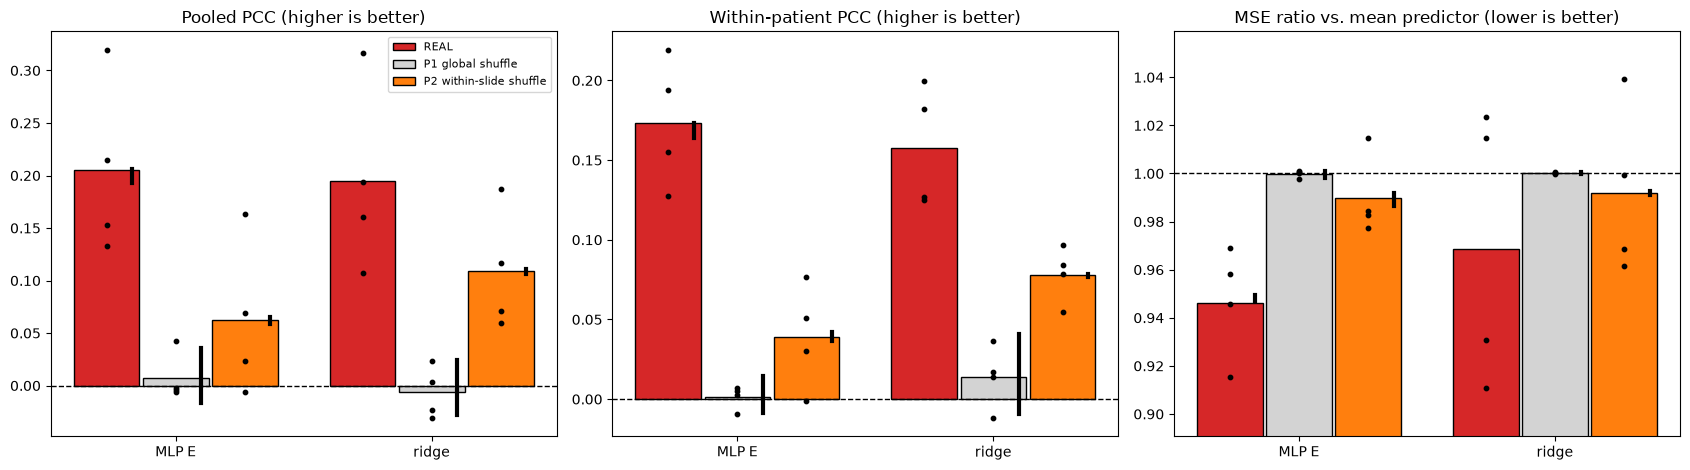

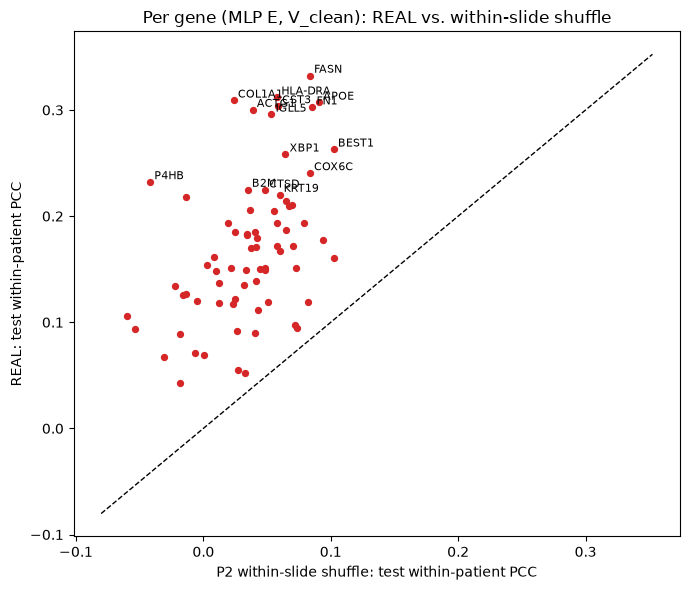

In [20]:
condition_colors = {"REAL": "tab:red", "P1": "lightgrey", "P2": "tab:orange"}
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
width = 0.27
for ax, metric, fold_metric, title in [(axes[0], "pooled_PCC", "PCC", "Pooled PCC (higher is better)"),
                                       (axes[1], "within_PCC", "PCC_within", "Within-patient PCC (higher is better)"),
                                       (axes[2], "MSE_ratio", "MSE_ratio", "MSE ratio vs. mean predictor (lower is better)")]:
    for m, model in enumerate(["E", "ridge"]):
        for c, condition in enumerate(CONDITIONS):
            row = summary[(summary["model"] == MODEL_NAMES[model]) & (summary["condition"] == CONDITIONS[condition])].iloc[0]
            x = m + (c - 1) * width
            ax.bar(x, row[metric], width * 0.95, color=condition_colors[condition], edgecolor="black",
                   label=CONDITIONS[condition] if m == 0 else None)
            values = fold_means[(fold_means["model"] == MODEL_NAMES[model]) & (fold_means["condition"] == condition)][fold_metric]
            ax.scatter(np.full(len(values), x), values, color="black", s=10, zorder=3)
            if pd.notna(row.get(f"{metric}_min")):
                ax.plot([x + 0.1, x + 0.1], [row[f"{metric}_min"], row[f"{metric}_max"]], color="black", linewidth=3)
    ax.axhline(1.0 if metric == "MSE_ratio" else 0.0, color="black", linestyle="--", linewidth=1)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["MLP E", "ridge"])
    ax.set_title(title)
ratio_values = fold_means["MSE_ratio"]
axes[2].set_ylim(ratio_values.min() - 0.02, max(1.0, ratio_values.max()) + 0.02)
axes[0].legend(fontsize=8)
plt.tight_layout()
save_figure("1_real_vs_shuffled.png")
plt.show()

per_gene = e_genes.groupby(["ensembl_id", "symbol"])[["within_PCC_REAL", "within_PCC_P2", "within_PCC_P1"]].mean().reset_index()
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(per_gene["within_PCC_P2"], per_gene["within_PCC_REAL"], s=18, color="tab:red")
low = min(per_gene[["within_PCC_P2", "within_PCC_REAL"]].min().min(), 0) - 0.02
high = per_gene[["within_PCC_P2", "within_PCC_REAL"]].max().max() + 0.02
ax.plot([low, high], [low, high], color="black", linestyle="--", linewidth=1)
for _, gene in per_gene.nlargest(15, "within_PCC_REAL").iterrows():
    ax.annotate(gene["symbol"], (gene["within_PCC_P2"], gene["within_PCC_REAL"]), fontsize=8,
                xytext=(3, 2), textcoords="offset points")
ax.set_xlabel("P2 within-slide shuffle: test within-patient PCC")
ax.set_ylabel("REAL: test within-patient PCC")
ax.set_title("Per gene (MLP E, V_clean): REAL vs. within-slide shuffle")
plt.tight_layout()
save_figure("2_genes_real_vs_p2.png")
plt.show()

## Step 15. Save results and add them to the log

`all_results.csv` gets 7 rows (`target` = raw, `gene_list` = V_clean): the mean predictor, and MLP E and ridge under REAL, P1 and P2 (P1/P2 = mean of the 3 draws). If this notebook is run again, its old rows are replaced instead of duplicated. MLP_JK_Best is not changed.

In [21]:
summary.to_csv(os.path.join(OUT_DIR, "summary.csv"), index=False)
run_scores.to_csv(os.path.join(OUT_DIR, "run_scores.csv"), index=False)
fold_scores.to_csv(os.path.join(OUT_DIR, "fold_scores.csv"), index=False)
gene_scores.to_csv(os.path.join(OUT_DIR, "gene_scores.csv"), index=False)
significance.to_csv(os.path.join(OUT_DIR, "significance.csv"), index=False)
counts.to_csv(os.path.join(OUT_DIR, "significance_counts.csv"), index=False)
reproduction_check.to_csv(os.path.join(OUT_DIR, "reproduction_check.csv"), index=False)
val_scores.to_csv(os.path.join(OUT_DIR, "validation_scores.csv"), index=False)
chosen_settings.to_csv(os.path.join(OUT_DIR, "chosen_settings.csv"), index=False)

settings = {
    "notebook": NOTEBOOK_NAME,
    "conditions": CONDITIONS,
    "shuffle_draws": SHUFFLE_DRAWS,
    "gene_rule": gene_rule,
    "neighbor_distance": NEIGHBOR_DISTANCE,
    "n_pcs": N_PCS,
    "n_folds": N_FOLDS,
    "n_inner_folds": N_INNER_FOLDS,
    "alphas": [float(a) for a in ALPHAS],
    "min_test_sd": MIN_TEST_SD,
    "seed": SEED,
    "hidden_size": HIDDEN_SIZE,
    "dropout": DROPOUT,
    "weight_decay": WEIGHT_DECAY,
    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "max_epochs": MAX_EPOCHS,
    "patience": PATIENCE,
    "shrink_factors": SHRINK_FACTORS,
    "n_val_groups": N_VAL_GROUPS,
    "n_final_seeds": N_FINAL_SEEDS,
    "device": str(device),
    "torch_version": torch.__version__,
}
with open(os.path.join(OUT_DIR, "settings.json"), "w") as f:
    json.dump(settings, f, indent=2)

if LOG_RESULTS:
    today = datetime.date.today().isoformat()
    log_rows = []
    for _, row in summary.iterrows():
        if row["model"] == "mean predictor":
            condition = "mean predictor"
        elif row["condition"] == "REAL":
            condition = f"{row['model']} | REAL"
        else:
            condition = f"{row['model']} | {row['condition']} (mean of {len(SHUFFLE_DRAWS)} draws)"
        log_rows.append({
            "notebook": NOTEBOOK_NAME,
            "condition": condition,
            "pooled_PCC": row.get("pooled_PCC", np.nan),
            "within_patient_PCC": row.get("within_PCC", np.nan),
            "NRMSE": row["NRMSE"],
            "mean_predictor_NRMSE": mean_overall["NRMSE"],
            "val_PCC": row.get("val_PCC", np.nan),
            "val_NRMSE": row.get("val_NRMSE", np.nan),
            "date": today,
            "target": "raw",
            "gene_list": GENE_LIST,
        })
    new_rows = pd.DataFrame(log_rows)
    old_rows = pd.read_csv(RESULTS_LOG)
    old_rows = old_rows[old_rows["notebook"] != NOTEBOOK_NAME]
    new_log = pd.concat([old_rows, new_rows], ignore_index=True)
    new_log.to_csv(RESULTS_LOG, index=False)
    print(new_log.tail(7).round(4).to_string(index=False))

print("\nSaved to", OUT_DIR)
for name in sorted(os.listdir(OUT_DIR)):
    print("  ", name)

 notebook                                                 condition  pooled_PCC  within_patient_PCC  NRMSE  mean_predictor_NRMSE  val_PCC  val_NRMSE       date target gene_list
MLP_JK_10                                            mean predictor         NaN                 NaN 1.0980                 1.098      NaN        NaN 2026-11-19    raw   V_clean
MLP_JK_10                                      E 5x5 average | REAL      0.2053              0.1731 1.0673                 1.098   0.2376     1.0804 2026-11-19    raw   V_clean
MLP_JK_10       E 5x5 average | P1 global shuffle (mean of 3 draws)      0.0074              0.0012 1.0978                 1.098  -0.0006     1.0029 2026-11-19    raw   V_clean
MLP_JK_10 E 5x5 average | P2 within-slide shuffle (mean of 3 draws)      0.0625              0.0388 1.0925                 1.098   0.1152     1.1046 2026-11-19    raw   V_clean
MLP_JK_10                                          ridge raw | REAL      0.1945              0.1573 1.0863         

## Summary in plain words: does the skill need the true image–expression pairing?

**Checks first:** REAL reproduced MLP_JK_Best exactly (test MSE 0.9451, pooled PCC 0.2053, validation PCC 0.2376; ridge 0.9674 / 0.1945). The shuffles do what they should: both keep every gene's training mean, P2 also keeps every slide's mean, and only the training labels were shuffled (test labels never).

### What each score means

| Score | What it means | Good vs. bad |
|---|---|---|
| **Pooled PCC** | Correlation between predicted and true expression over all test spots (rewards getting differences between slides right too) | 0 = no relation; higher is better |
| **Within-patient PCC** | The same inside one patient at a time (each patient has ~3 slides) | 0 = no relation; higher is better |
| **MSE ratio** | Test MSE ÷ the mean predictor's (always guessing the training average) | 1 = no better than guessing; lower is better |
| **Level / pattern error** | The MSE split into "whole slide shifted" and "what's left inside each slide" (MLP_JK_06) | Lower is better |

### Results (test patients, 4 folds; P1 and P2 = mean of 3 shuffle draws, range in brackets)

| Model | Condition | Pooled PCC | Within-patient PCC | MSE ratio | Level error | Pattern error |
|---|---|---|---|---|---|---|
| mean predictor | – | – | – | 1.000 | 0.592 | 0.407 |
| **MLP E** | **REAL** | **0.205** | **0.173** | **0.946** | **0.555** | **0.390** |
| MLP E | P1 global shuffle | 0.007 [−0.017, 0.036] | 0.001 [−0.009, 0.014] | 1.000 [0.998, 1.001] | 0.591 | 0.407 |
| MLP E | P2 within-slide shuffle | 0.063 [0.058, 0.066] | 0.039 [0.036, 0.042] | 0.990 [0.987, 0.992] | 0.581 | 0.408 |
| ridge | REAL | 0.195 | 0.157 | 0.969 | 0.552 | 0.416 |
| ridge | P1 global shuffle | −0.007 [−0.028, 0.025] | 0.014 [−0.009, 0.041] | 1.000 [1.000, 1.001] | 0.592 | 0.407 |
| ridge | P2 within-slide shuffle | 0.109 [0.107, 0.111] | 0.078 [0.076, 0.079] | 0.992 [0.991, 0.993] | 0.571 | 0.420 |

**1. Yes, the skill disappears when the pairing is broken (P1).** With globally shuffled labels, both PCCs drop to about 0 and the MSE equals the mean predictor's (ratio 1.000), exactly as expected. REAL beats **all 3 P1 draws in all 4 folds** on pooled PCC, within-patient PCC and MSE ratio (MLP E), by at least 0.07 in pooled PCC and 0.10 in within-patient PCC. So the model's skill comes from the true image–expression pairing, not from something in the pipeline.

**2. Most of the skill is spot-level; a smaller part is slide-level (P2).** When each slide keeps its own level but the spots inside it are scrambled, MLP E keeps:
- about **30% of its pooled PCC** (0.063 of 0.205),
- about **19% of its MSE gain** over the mean predictor (1 − 0.990 = 0.010 of 0.054),
- about **22% of its within-patient PCC** (0.039 of 0.173).

REAL beats all 3 P2 draws in all 4 folds on every score (MLP E).

**3. The error split confirms where P2's skill comes from.** P2 lowers only the **level** error (0.592 → 0.581); its **pattern** error stays at the mean predictor's (0.408 vs. 0.407). REAL lowers both (level −0.037, pattern −0.017). So P2 learns which slides are "high" or "low" from the images (e.g. staining, tissue type), and that carries over to new slides a little, but it learns nothing about where in the tissue a gene is high.

**Why P2's within-patient PCC isn't exactly 0:** each patient has about 3 slides, so "within patient" still includes differences **between** that patient's slides, which P2 can partly get right.

**4. Ridge relies more on slide-level information than the MLP.** Under P2, ridge keeps 56% of its pooled PCC and 49% of its within-patient PCC (vs. 30% and 22% for the MLP). The MLP's extra skill over ridge is in the spot-level pattern (REAL pattern error 0.390 vs. ridge 0.416). On MSE ratio, ridge REAL beats all P1 draws in only 2 of 4 folds, because in folds 0 and 2 ridge REAL is itself slightly worse than the mean predictor.

**Bottom line:** the sanity check passes. The model's skill depends on the true pairing between each spot's image and its expression (it vanishes under a global shuffle), and roughly 70–80% of it is spot-level: it comes from reading **where** in the tissue genes are high, not just which slide is which. Every V_clean gene does better under REAL than under P2 (Figure 2).

MLP_JK_Best was not changed.